1. Load the Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("credit_risk_dataset.csv")

In [3]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


2. Exploratory Data Analysis (EDA)

In [4]:
df.shape

(32581, 12)

In [5]:
df.columns


Index(['person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_default_on_file', 'cb_person_cred_hist_length'],
      dtype='object')

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [7]:
df.isnull().sum()

person_age                       0
person_income                    0
person_home_ownership            0
person_emp_length              895
loan_intent                      0
loan_grade                       0
loan_amnt                        0
loan_int_rate                 3116
loan_status                      0
loan_percent_income              0
cb_person_default_on_file        0
cb_person_cred_hist_length       0
dtype: int64

In [8]:
df["loan_status"].value_counts()

loan_status
0    25473
1     7108
Name: count, dtype: int64

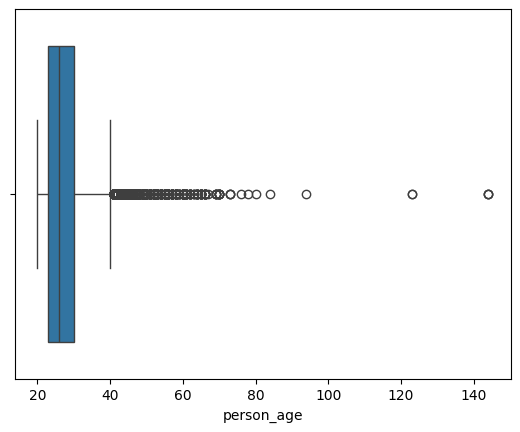

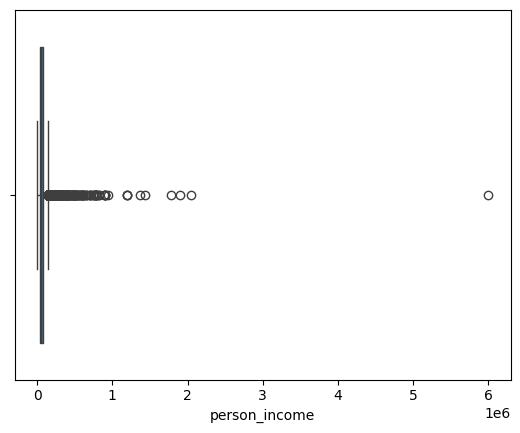

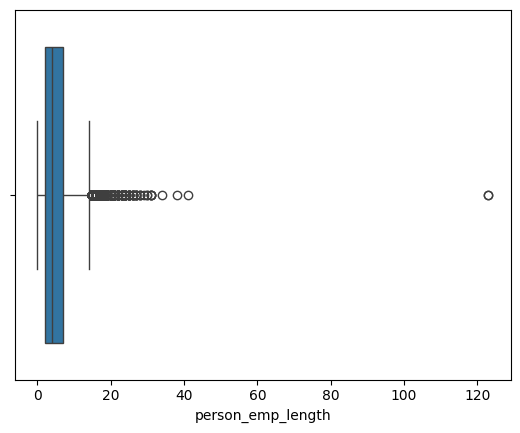

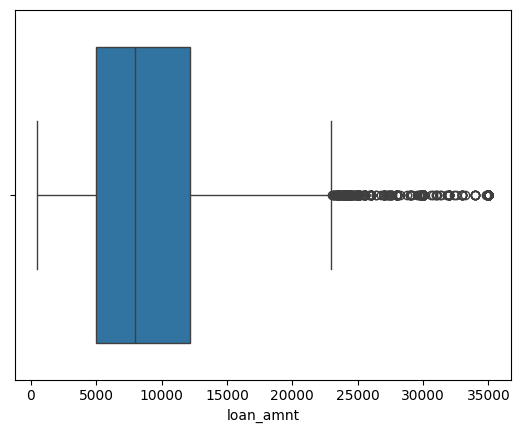

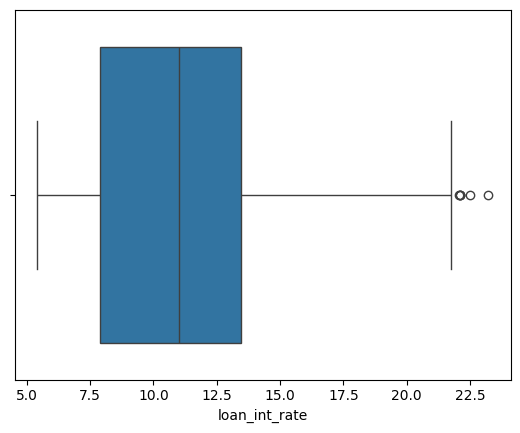

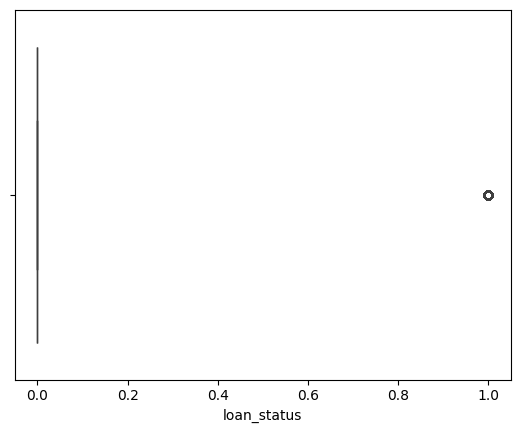

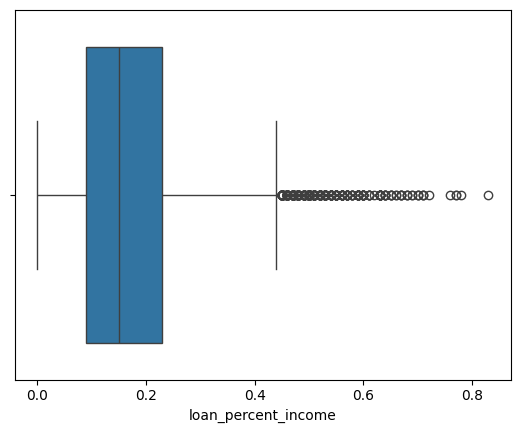

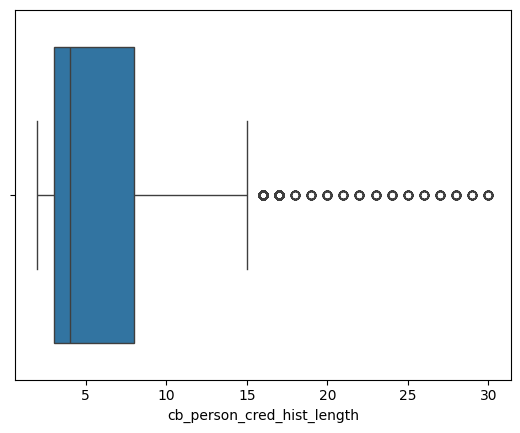

In [9]:
numerical_col = df.select_dtypes(include = np.number).columns

for i in numerical_col:
    sns.boxplot(x = df[i])
    plt.show()

In [10]:
(df["person_age"]>100).sum()

np.int64(5)

In [11]:
(df["person_emp_length"]>60).sum()

np.int64(2)

In [12]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,31686.000000,32581.000000,29465.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.789686,9589.371106,11.011695,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.142630,6322.086646,3.240459,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,7.900000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.470000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


To check correlation between numerical columns

<Axes: >

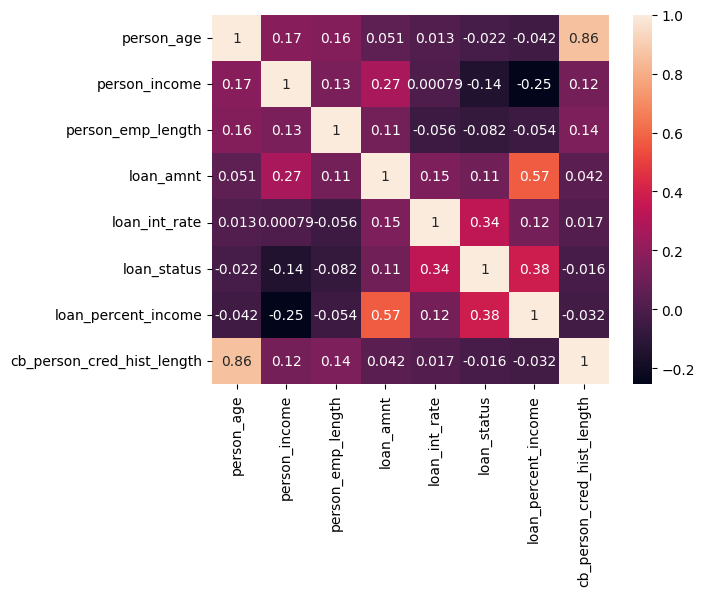

In [13]:
sns.heatmap(df.corr(numeric_only = True), annot = True)

3. Data Validation & Outlier Handling

In [14]:
df1 = df.copy()

print(f"Original Rows : {df1.shape[0]}")

df1.drop_duplicates(inplace=True)


df1 = df1[(df1["person_age"] >= 18) & (df1["person_age"] <= 100)]


df1 = df1[df1["person_emp_length"].isna() | (df1["person_emp_length"] <= 60)]
df1 = df1[df1["person_emp_length"].isna() | (df1["person_emp_length"] <= df1["person_age"])]

df1 = df1[df1["loan_amnt"] > 0]

print(f"Rows after cleaning : {df1.shape[0]}")

Original Rows : 32581
Rows after cleaning : 32409


4. Features, Target & Train-Test Split

In [15]:
x = df1.drop("loan_status", axis =1)
y = df1["loan_status"]

In [16]:
from sklearn.model_selection import train_test_split

x_train, x_test,y_train, y_test = train_test_split(x,y,test_size = 0.2, random_state = 42, stratify = y)

In [17]:
numeric_cols = ['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

categorical_cols = ['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']
     

5. Handle Class Imbalance

In [18]:
# loan_status: 0 = no default, 1 = default. The dataset is imbalanced (far more 0s than 1s),
# so we use scale_pos_weight to balance the classes.

neg, pos = np.bincount(y_train)
scale_weights = neg / pos

6. Data preprocessing - Pipelines & Column Transfer

In [19]:
from sklearn. preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer

 

Preprocessing for Logistic Regression

In [20]:
preprocessor_lr = ColumnTransformer(
    transformers = [("num", Pipeline(steps = [("imputer", SimpleImputer(strategy = "median")),
                                             ("scaler", StandardScaler())]), numeric_cols), 
                   
                   ('cat', Pipeline(steps = [("imputer", SimpleImputer(strategy = "constant", fill_value = "missing")),
                                            ("onehot", OneHotEncoder(handle_unknown = "ignore"))]), categorical_cols)
    ]
)

Preprocessing for xgBoost

In [21]:
preprocessor_xg = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[("imputer", SimpleImputer(strategy="median"))]), numeric_cols),
        ("cat", Pipeline(steps=[
            ("imputer", SimpleImputer(strategy="constant", fill_value="missing")),
            ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
        ]), categorical_cols)
    ]
)

7. Evaluation Helper Function

In [22]:
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, precision_recall_curve,
                             roc_auc_score, average_precision_score)

def evaluate_model(model_name, model, X_test, y_test, threshold=None):
    y_pred_prob = model.predict_proba(X_test)[:, 1]

    cutoff = 0.5 if threshold is None else threshold
    y_pred = (y_pred_prob >= cutoff).astype(int)

    # Metrics
    accuracy  = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)   # when model says 1, how often is it really 1
    recall    = recall_score(y_test, y_pred)      # of the actual 1s, how many did the model catch
    f1        = f1_score(y_test, y_pred)
    roc_auc   = roc_auc_score(y_test, y_pred_prob)
    pr_auc    = average_precision_score(y_test, y_pred_prob)

    conf_matrix  = confusion_matrix(y_test, y_pred)
    class_report = classification_report(y_test, y_pred)

    print(f"{model_name} Metrics:")
    print(f"Threshold used : {cutoff:.2f}")
    print(f"Accuracy  : {accuracy:.2f}")
    print(f"Precision : {precision:.2f}")
    print(f"Recall    : {recall:.2f}")
    print(f"F1        : {f1:.2f}")
    print(f"ROC-AUC   : {roc_auc:.3f}")
    print(f"PR-AUC    : {pr_auc:.3f}")
    print()
    print(f"{model_name} Classification Report:")
    print(class_report)

    # Confusion matrix
    sns.heatmap(conf_matrix, annot=True, fmt="d")
    plt.title(f"{model_name} Confusion Matrix")
    plt.ylabel("Actual Values")
    plt.xlabel("Predicted Values")
    plt.show()

    # Precision-Recall curve
    prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_pred_prob)
    plt.plot(rec_curve, prec_curve)
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title(f"{model_name} Precision-Recall Curve")
    plt.show()

8. Stratified Cross- Validation is a technique used in machine learning to evaluate the performance of a model while ensuring that the distribution of classes in the training and validation sets is similar to that of the original dataset. This is particularly important when dealing with imbalanced datasets, where one class may be significantly more prevalent than others.

In [23]:
from sklearn.model_selection import StratifiedKFold, cross_validate
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {'roc_auc':'roc_auc', 'accuracy':'accuracy', 'precision':'precision', 'recall':'recall', 'f1':'f1'}
     

In [24]:
#Logistic Regression
from sklearn.linear_model import LogisticRegression
lr_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_lr),
    ("classifier", LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))
])
     

In [25]:
from xgboost import XGBClassifier

xgb_cv_pipeline = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(
        n_estimators=300, max_depth=5, learning_rate=0.1,
        scale_pos_weight=scale_weights, random_state=42
    ))
])

In [26]:
for cv_name, pipe in [("Logistic Regression", lr_cv_pipeline),
                      ("XGBoost", xgb_cv_pipeline)]:

    cv_results = cross_validate(pipe, x_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)

    print(cv_name)
    for metric in scoring:
        print(f"{metric} : {cv_results['test_' + metric].mean():.4f}")
    print()

Logistic Regression
roc_auc : 0.8702
accuracy : 0.8123
precision : 0.5504
recall : 0.7755
f1 : 0.6438

XGBoost
roc_auc : 0.9471
accuracy : 0.9148
precision : 0.8121
recall : 0.7942
f1 : 0.8030



9. Baseline Model - Logistic Regression

In [27]:
from sklearn.pipeline import Pipeline
baseline_model = Pipeline([
    ('preprocessor', preprocessor_lr),
    ('classifier', LogisticRegression(class_weight= "balanced"))
])
baseline_model.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


Baseline Logistic Model Metrics:
Threshold used : 0.50
Accuracy  : 0.81
Precision : 0.54
Recall    : 0.78
F1        : 0.64
ROC-AUC   : 0.872
PR-AUC    : 0.708

Baseline Logistic Model Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.81      0.87      5064
           1       0.54      0.78      0.64      1418

    accuracy                           0.81      6482
   macro avg       0.73      0.80      0.75      6482
weighted avg       0.84      0.81      0.82      6482



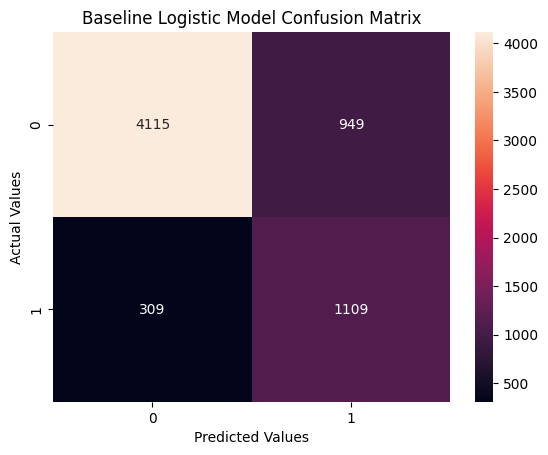

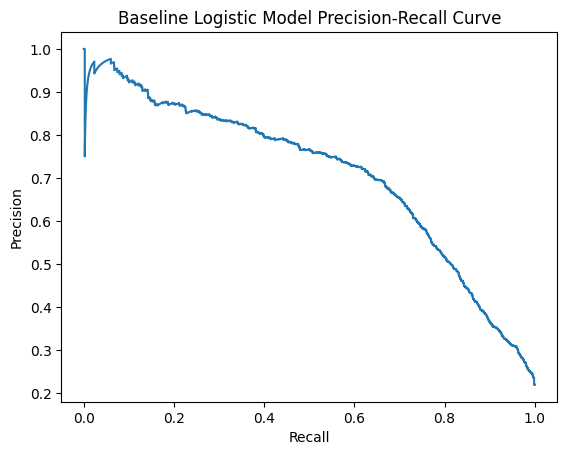

In [28]:

#Evaluate the Logistic Model.
evaluate_model("Baseline Logistic Model", baseline_model ,x_test, y_test)

10. XGBoost Hyperparameter Tuning

In [29]:
xg_model = Pipeline([
    ('preprocessor', preprocessor_xg),
    ('classifier', XGBClassifier(learning_rate=0.1,
        scale_pos_weight=scale_weights,random_state=42))
])
xg_model.fit(x_train, y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [30]:
from sklearn.model_selection import RandomizedSearchCV
from scipy.stats import uniform, randint

param_grid = {
    "classifier__n_estimators": randint(150, 600),
    "classifier__max_depth" : randint(3,9),
    "classifier__learning_rate" : uniform(0.01, 0.5),
    "classifier__subsample": uniform(0.6,0.4), #Rows sampling
    "classifier__colsample_bytree" :uniform(0.6,0.4), #column sampling
    "classifier__min_child_weight": randint(1, 10),
    "classifier__gamma": uniform(0 , 5)
}
# lower gamma -> more splits -> complex tree -> higher overfitting risk
# higher gamma -> less splits ->  simpler tree -> low overfitting
     

In [31]:
random_search = RandomizedSearchCV(
    xg_model,
    param_grid,
    n_iter=150,
    cv=cv,
    scoring="average_precision",
    n_jobs=-1,
    verbose=1
)

random_search.fit(x_train, y_train)

Fitting 5 folds for each of 150 candidates, totalling 750 fits


,estimator,"Pipeline(step...=None, ...))])"
,param_distributions,"{'classifier__colsample_bytree': <scipy.stats....00200D0726D50>, 'classifier__gamma': <scipy.stats....00200D0364C30>, 'classifier__learning_rate': <scipy.stats....00200D0299400>, 'classifier__max_depth': <scipy.stats....00200D0726990>, ...}"
,n_iter,150
,scoring,'average_precision'
,n_jobs,-1
,refit,True
,cv,StratifiedKFo... shuffle=True)
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,None
,error_score,nan


In [32]:
print(f"Best CV average precision (PR-AUC) after tuning : {random_search.best_score_:.3f}")

Best CV average precision (PR-AUC) after tuning : 0.904


In [33]:

random_search.best_params_

{'classifier__colsample_bytree': np.float64(0.8469124365987285),
 'classifier__gamma': np.float64(0.030565491964716363),
 'classifier__learning_rate': np.float64(0.08425172968423993),
 'classifier__max_depth': 7,
 'classifier__min_child_weight': 7,
 'classifier__n_estimators': 394,
 'classifier__subsample': np.float64(0.8722990730886488)}

11. Compare Both Model

Logistic Regression Metrics:
Threshold used : 0.50
Accuracy  : 0.81
Precision : 0.54
Recall    : 0.78
F1        : 0.64
ROC-AUC   : 0.872
PR-AUC    : 0.708

Logistic Regression Classification Report:
              precision    recall  f1-score   support

           0       0.93      0.81      0.87      5064
           1       0.54      0.78      0.64      1418

    accuracy                           0.81      6482
   macro avg       0.73      0.80      0.75      6482
weighted avg       0.84      0.81      0.82      6482



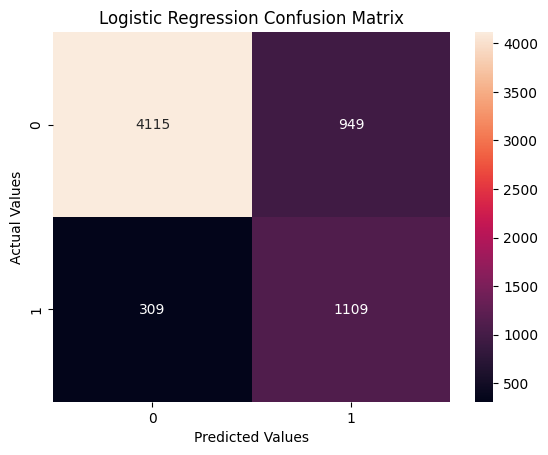

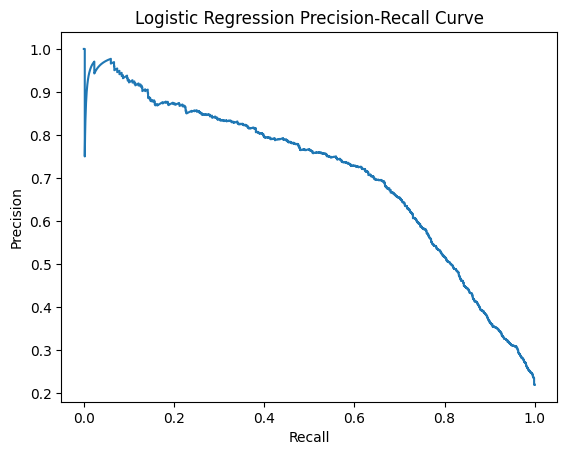

In [34]:
evaluate_model("Logistic Regression", baseline_model, x_test, y_test)

XGBoost Metrics:
Threshold used : 0.50
Accuracy  : 0.93
Precision : 0.84
Recall    : 0.81
F1        : 0.83
ROC-AUC   : 0.953
PR-AUC    : 0.913

XGBoost Classification Report:
              precision    recall  f1-score   support

           0       0.95      0.96      0.95      5064
           1       0.84      0.81      0.83      1418

    accuracy                           0.93      6482
   macro avg       0.89      0.89      0.89      6482
weighted avg       0.92      0.93      0.92      6482



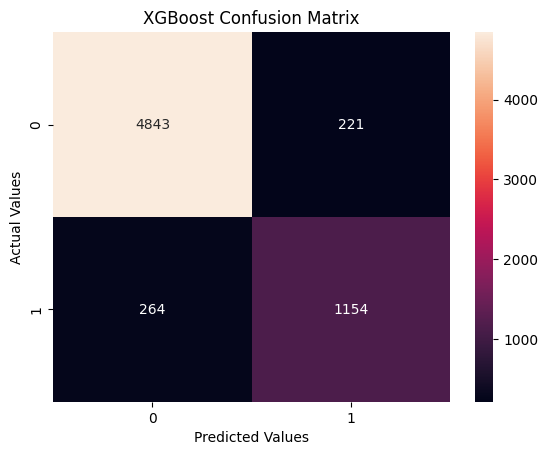

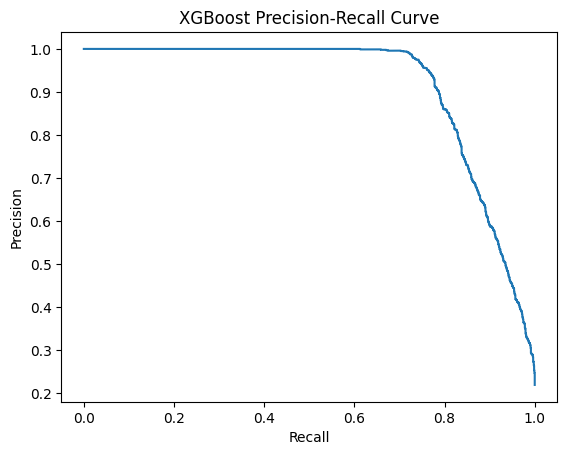

In [35]:

#Passing the XGBoost model after performing Hyperparameter Tuning
evaluate_model("XGBoost", random_search, x_test, y_test)

12. Probability Calibration


In [36]:

"""
Methods by which we can fix the poorly calibrated model.
1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.
2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)
3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature
"""
    

'\nMethods by which we can fix the poorly calibrated model.\n1. Platt Scaling/ Sigmoid -> Adjust the probabilites using a sigmoid curve.\n2. Isotonic Regression -> Learn a flexible mapping from old prob. - better prob. (non-linear calibartion)\n3. Temperature Scaling -> Adjust the confidence of neural-network predictions using one temperature\n'

In [37]:
#1. Calibrated XGBoost model
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
best_model = random_search.best_estimator_
calibrated_model = CalibratedClassifierCV(
    best_model,
    method="sigmoid",
    cv=5
)

calibrated_model.fit(x_train, y_train)
     

,estimator,"Pipeline(step...=None, ...))])"
,method,'sigmoid'
,cv,5
,n_jobs,None
,ensemble,'auto'
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False


In [38]:
#2. Get probabilities (same tuned model, before vs after calibration)
from sklearn.metrics import brier_score_loss, log_loss

uncalibrated = random_search.best_estimator_.predict_proba(x_test)[:, 1]
calibrated   = calibrated_model.predict_proba(x_test)[:, 1]

print(f"Brier score - uncalibrated: {brier_score_loss(y_test, uncalibrated):.4f} | calibrated: {brier_score_loss(y_test, calibrated):.4f}")
print(f"Log loss    - uncalibrated: {log_loss(y_test, uncalibrated):.4f} | calibrated: {log_loss(y_test, calibrated):.4f}")
     

Brier score - uncalibrated: 0.0584 | calibrated: 0.0508
Log loss    - uncalibrated: 0.2012 | calibrated: 0.1887


In [39]:

#3. create calibration curves
actual_uncal, predicted_uncal = calibration_curve(y_test, uncalibrated, n_bins=10)

In [40]:

actual_cal, predicted_cal  = calibration_curve(y_test, calibrated, n_bins=10)

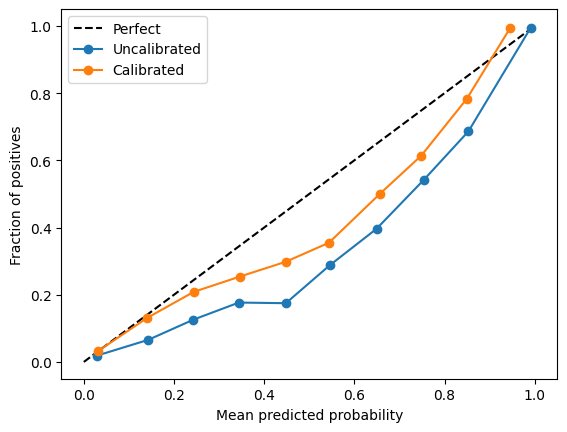

In [41]:
#4. plot
plt.plot([0,1], [0,1], 'k--', label="Perfect")
plt.plot(
    predicted_uncal,
    actual_uncal,
    "o-",
    label = "Uncalibrated"
)

plt.plot(
    predicted_cal,
    actual_cal,
    "o-",
    label = "Calibrated"
)

plt.xlabel("Mean predicted probability") 
plt.ylabel("Fraction of positives")

plt.legend()

13. Optimizing Threshold

In [42]:
from sklearn.model_selection import cross_val_predict


final_recipe = CalibratedClassifierCV(random_search.best_estimator_, method="sigmoid", cv=5)

oof_prob = cross_val_predict(
    final_recipe, x_train, y_train, cv=cv, method="predict_proba", n_jobs=-1
)[:, 1]

precisions, recalls, thresholds = precision_recall_curve(y_train, oof_prob)
f1_scores = 2 * precisions * recalls / (precisions + recalls + 1e-9)

best_idx = np.argmax(f1_scores[:-1])
best_threshold = float(thresholds[best_idx])

print(f"Best threshold (max F1, from training OOF): {best_threshold:.3f}")
print(f"OOF precision: {precisions[best_idx]:.2f} | OOF recall: {recalls[best_idx]:.2f}")

Best threshold (max F1, from training OOF): 0.657
OOF precision: 0.95 | OOF recall: 0.73


In [43]:
target_recall = 0.85   # change to what the business needs
ok = np.where(recalls[:-1] >= target_recall)[0]
best_threshold = float(thresholds[ok[-1]])   # highest threshold that still meets the recall target
print(f"Threshold for recall >= {target_recall}: {best_threshold:.3f}")

Threshold for recall >= 0.85: 0.167


In [44]:
target_recall = 0.85   # change to what the business needs
ok = np.where(recalls[:-1] >= target_recall)[0]
best_threshold = float(thresholds[ok[-1]])   # highest threshold that still meets the recall target
print(f"Threshold for recall >= {target_recall}: {best_threshold:.3f}")

Threshold for recall >= 0.85: 0.167


14. SHAP Interpretation - Global & Local

In [45]:

#1. Install SHAP if not exists
! pip install shap
import shap


[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Defaulting to user installation because normal site-packages is not writeable


In [46]:
#2. Get the tuned XGBoost pipeline and its classifier
xgb_pipeline = random_search.best_estimator_
xgb_classifier = xgb_pipeline.named_steps['classifier']

In [47]:
#3. Transform X_test using the same preprocessing used for training
X_test_transformed = xgb_pipeline.named_steps['preprocessor'].transform(x_test)

In [48]:

#4. Get feature names after one-hot encoding, so plots are readable
feature_names = xgb_pipeline.named_steps['preprocessor'].get_feature_names_out()

In [49]:

#5. Convert to a dataframe for cleaner SHAP plots
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)
     

In [50]:
#6. Create SHAP explainer built for tree-based model
explainer = shap.TreeExplainer(xgb_classifier)
     

In [51]:

#7. Calculate SHAP values for every row in the test set
shap_values = explainer.shap_values(X_test_df)
shap_values
     

array([[ 1.99974775e-01,  2.47098804e-01, -2.34127060e-01, ...,
        -7.80971441e-03, -3.21176350e-02,  2.90357135e-03],
       [ 2.88346447e-02, -8.91565502e-01, -1.88672423e-01, ...,
        -8.15532357e-03, -7.45689049e-02,  2.03827076e-04],
       [-1.99632809e-01,  1.02255821e-01, -1.65331542e-01, ...,
        -7.40793999e-03, -1.42692737e-02, -2.73184525e-03],
       ...,
       [ 7.12721050e-03,  6.84421182e-01, -1.19171426e-01, ...,
        -7.01329112e-03,  3.58986645e-03, -4.47925320e-03],
       [-3.49786505e-02, -2.04960346e+00, -3.12270105e-01, ...,
        -8.59275274e-03,  4.30270052e-03, -2.20225239e-03],
       [-9.52425525e-02, -6.21377647e-01,  1.90869756e-02, ...,
        -9.15622991e-03, -2.99722217e-02, -2.99068238e-03]],
      shape=(6482, 26), dtype=float32)

Global Explaination

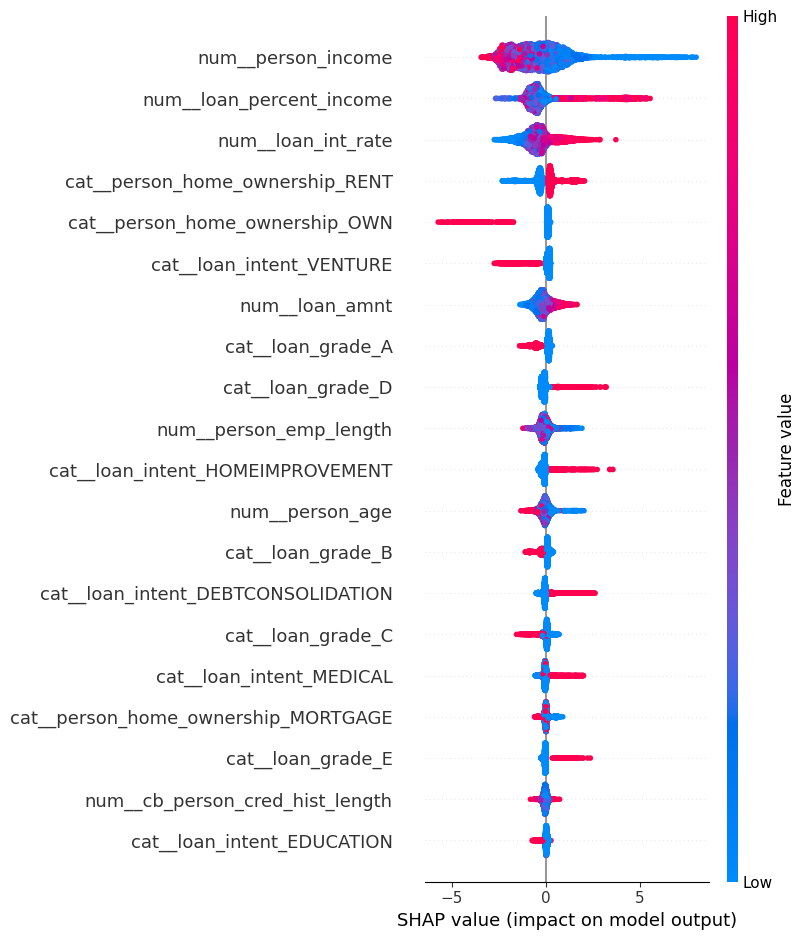

In [52]:

shap.summary_plot(shap_values, X_test_df)

Local Explanation

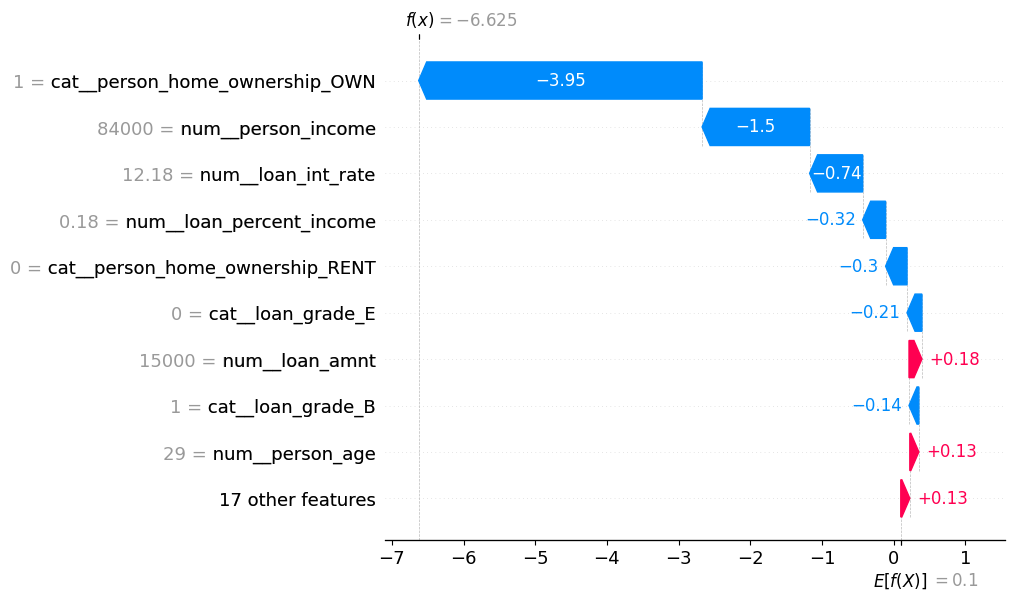

In [53]:
# 1. Pick one row to explain, e.g. the 5th applicant in the test set
row_index = 5

#2. Draw a waterfall plot showing how each feature pushed the prediction up or down.
shap.plots.waterfall(
    shap.Explanation(
        values = shap_values[row_index],
        base_values = explainer.expected_value,
        data = X_test_df.iloc[row_index],
        feature_names = feature_names
    )
)

15. Analyzing False Positives & False Negatives

In [54]:
#Get predictions from the final (calibrated) model using the chosen threshold
y_prob_test = calibrated_model.predict_proba(x_test)[:, 1]
y_pred = (y_prob_test >= best_threshold).astype(int)

In [55]:
#Create a dataframe to easily compare the actual and predicted values
result_df = x_test.copy()
result_df['actual'] = y_test
result_df['predicted'] = y_pred

In [56]:
#Identify False Positive : Model Predicted 1, but the actual was 0
false_positive = result_df[(result_df['actual']== 0) & (result_df['predicted']== 1)]

#Identify False Negative : Model Predicted 0, but the actual was 1
false_negative = result_df[(result_df['actual']== 1) & (result_df['predicted']== 0)]

In [57]:
print(f"False Positive : {len(false_positive)}")
print(f"False Negative : {len(false_negative)}")
     

False Positive : 526
False Negative : 186


In [58]:
# False Positive: model predicted default, but the applicant would have repaid.
#   -> lender loses a good customer (lost interest income).
# False Negative: model predicted no default, but the applicant defaulted.
#   -> lender loses principal, usually the costlier mistake.
# So the threshold should favour recall (fewer false negatives), balanced against
# how many good applicants we are willing to reject.

16. Save the final Model

In [59]:
import joblib

joblib.dump(calibrated_model, "model.pkl")
joblib.dump(best_threshold, "best_threshold.pkl")

['best_threshold.pkl']